## Listes de 9 questions

Quand et comment les clients commandent-ils généralement ?  

Quels produits faut-il mettre en avant le samedi ?  

Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

Quel article les clients ajoutent-ils en premier à leur panier ?

Quels produits ont le plus de chances d’être commandés à nouveau ?

Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Ouverture des fichiers 

In [4]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

In [5]:
display(df_aisles.head())
display(df_departments.head())
display(df_order_products.head())
display(df_orders.head())
display(df_products.head())

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


,order_id,product_id,add_to_cart_order,reordered
0,2,33120.0,1.0,1.0
1,2,28985.0,2.0,1.0
2,2,9327.0,3.0,0.0
3,2,45918.0,4.0,1.0
4,2,30035.0,5.0,0.0


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1.0,1.0,2.0,8.0,NaN
1,2398795,1.0,2.0,3.0,7.0,15.0
2,473747,1.0,3.0,3.0,12.0,21.0
3,2254736,1.0,4.0,4.0,7.0,29.0
4,431534,1.0,5.0,4.0,15.0,28.0


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [6]:
display(df_aisles.shape)
display(df_departments.shape)
display(df_order_products.shape)
display(df_orders.shape)
display(df_products.shape)

(134, 2)

(21, 2)

(13692886, 4)

(1444444, 6)

(49688, 4)

Vérifications qu'il n'y a pas de valeurs nul.

In [7]:
df_aisles.isnull().sum()
df_departments.isnull().sum()
df_order_products.isnull().sum()
df_orders.isnull().sum()
df_products.isnull().sum()

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

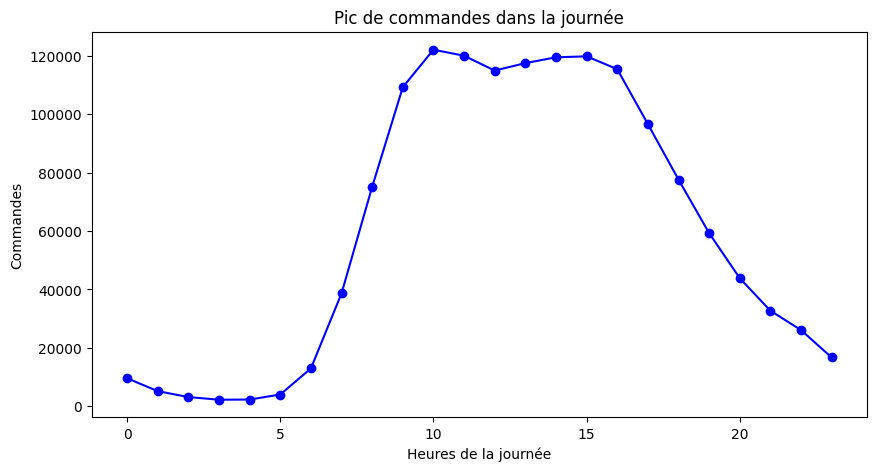

In [8]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_hour.index, df_orders_hour.values, marker="o", color="blue")
plt.title("Pic de commandes dans la journée")
plt.xlabel("Heures de la journée")
plt.ylabel("Commandes")
plt.show()

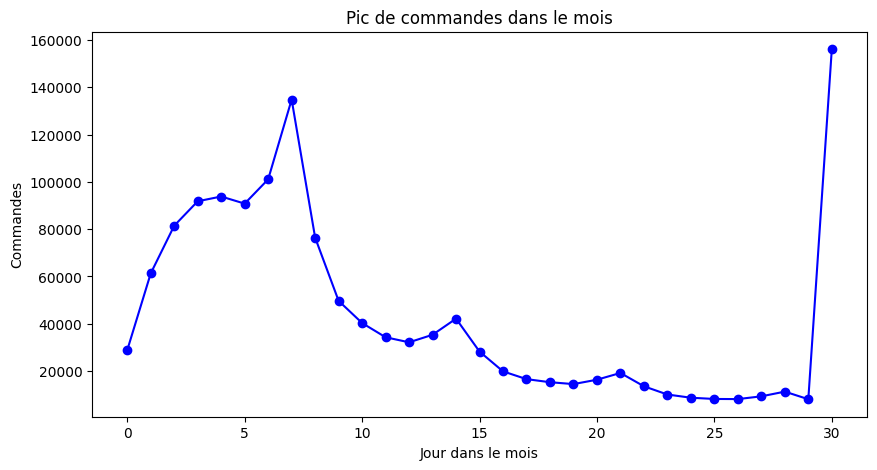

In [9]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_day.index, df_orders_day.values, marker="o", color="blue")
plt.title("Pic de commandes dans le mois")
plt.xlabel("Jour dans le mois")
plt.ylabel("Commandes")
plt.show()

In [10]:
print("test")

test


## Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

In [23]:
cat_food_ids = df_products[df_products["product_name"].str.contains("Cat Food", na=False)]["product_id"]

cat_orders = df_order_products[df_order_products["product_id"].isin(cat_food_ids)]

cat_orders = cat_orders["order_id"]

orders_with_cat = df_orders[df_orders["order_id"].isin(cat_orders)]

orders_matin = orders_with_cat[
    (orders_with_cat["order_hour_of_day"] >= 7) &
    (orders_with_cat["order_hour_of_day"] <= 12)
]

orders_matin_cat = len(orders_matin)

print(orders_matin_cat)

# Dog Food

dog_food_ids = df_products[df_products["product_name"].str.contains("Dog Food", na=False)]["product_id"]

dog_orders = df_order_products[df_order_products["product_id"].isin(dog_food_ids)]

dog_orders = dog_orders["order_id"]

orders_with_dog = df_orders[df_orders["order_id"].isin(dog_orders)]

orders_matin = orders_with_dog[
    (orders_with_dog["order_hour_of_day"] >= 17) &
    (orders_with_dog["order_hour_of_day"] <= 22)
]

orders_soir_dog = len(orders_matin)

print(orders_soir_dog)


3595
1404


In [24]:
if orders_matin_cat > orders_soir_dog:
    print("Oui, les clients commandent plus de nourriture pour chats le matin.")
else:
    print("Non, les clients commandent plus de nourriture pour chiens le soir.")


Oui, les clients commandent plus de nourriture pour chats le matin.


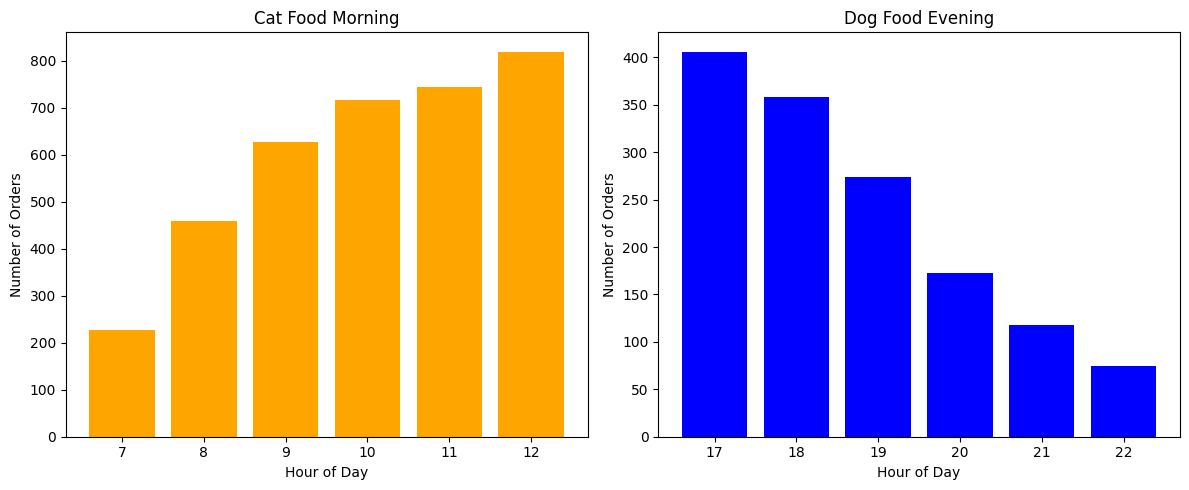

In [ ]:

cat_hours = orders_with_cat[
    (orders_with_cat["order_hour_of_day"] >= 7) &
    (orders_with_cat["order_hour_of_day"] <= 12)
]["order_hour_of_day"].value_counts().sort_index()


dog_hours = orders_with_dog[
    (orders_with_dog["order_hour_of_day"] >= 17) &
    (orders_with_dog["order_hour_of_day"] <= 22)
]["order_hour_of_day"].value_counts().sort_index()


fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Cat Food

axes[0].bar(cat_hours.index, cat_hours.values, color='orange')
axes[0].set_title('Cat Food Morning')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Number of Orders')
axes[0].set_xticks(range(7,13)) 

# Dog Food

axes[1].bar(dog_hours.index, dog_hours.values, color='blue')
axes[1].set_title('Dog Food Evening')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Number of Orders')
axes[1].set_xticks(range(17,23))  

plt.tight_layout()
plt.show()


 - Nombre moyen de commandes de nourriture pour chats le matin (7h-12h) : **3595**

 - Nombre moyen de commandes de nourriture pour chiens le soir (17h-22h) : **1404**

Conclusion : `Les clients commandent beaucoup plus de nourriture pour chats le matin que de nourriture pour chiens le soir.`

## Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?